# 07 — Gaussian Blur: Spatial Smoothing and Frequency Response

Gaussian smoothing averages nearby samples with weights that decrease smoothly with distance. This notebook connects its spatial kernel to its low-pass frequency response and contrasts it with uniform averaging.

## Learning objectives
- Construct normalized discrete Gaussian kernels from the continuous formula.
- Distinguish sigma, finite kernel support, and boundary extension.
- Verify separable NumPy filtering against OpenCV using matched conventions.
- Compare mean and Gaussian filters on structure and controlled noise.
- Explain smoothing through spatial frequency and sinusoidal attenuation.

Run all cells in order. The original sigma-sweep experiment and its saved output are unchanged. Supplementary experiments use the same bundled `skimage.data.camera()` image and reproducible synthetic signals.

## 1. Gaussian model and discrete kernels

The normalized continuous isotropic Gaussian in two dimensions is

$$G_\sigma(x,y)=\frac{1}{2\pi\sigma^2}\exp\left(-\frac{x^2+y^2}{2\sigma^2}\right),\quad \sigma>0.$$

For sampled images, sigma is measured in pixels. The continuous prefactor alone does not guarantee a finite sampled kernel sums to one. For integer offsets $-r\leq u,v\leq r$, normalize explicitly:

$$K_\sigma[u,v]=\frac{\exp(-(u^2+v^2)/(2\sigma^2))}{\sum_{a=-r}^r\sum_{b=-r}^r\exp(-(a^2+b^2)/(2\sigma^2))}.$$

A practical support is $r=\lceil3\sigma\rceil$, so the odd kernel size is $2r+1$. Truncation is an approximation: sigma controls the underlying weight profile, while radius controls how much of its tail is retained. A fixed small kernel cannot represent arbitrarily large sigma faithfully.

Spatial smoothing is a weighted sum,

$$J[i,j]=\sum_{u=-r}^r\sum_{v=-r}^r K_\sigma[u,v]I[i-u,j-v].$$

Positive weights sum to one, preserving constant regions under a constant-preserving boundary extension. The Gaussian is symmetric, so convolution and correlation agree. It is also separable: $K_\sigma[u,v]=g_\sigma[u]g_\sigma[v]$. Two 1D passes reduce per-pixel work from $O(k^2)$ to $O(k)$ for kernel width $k$.

## 2. Original experiment — varying sigma

The preserved code below increases both sigma and kernel support according to the three-sigma rule. Predict which image will lose the most fine structure. OpenCV receives uint8 input and returns uint8 output, so results are rounded to integer levels. Its default boundary is `BORDER_REFLECT_101`; later comparisons make the boundary and floating dtype explicit.

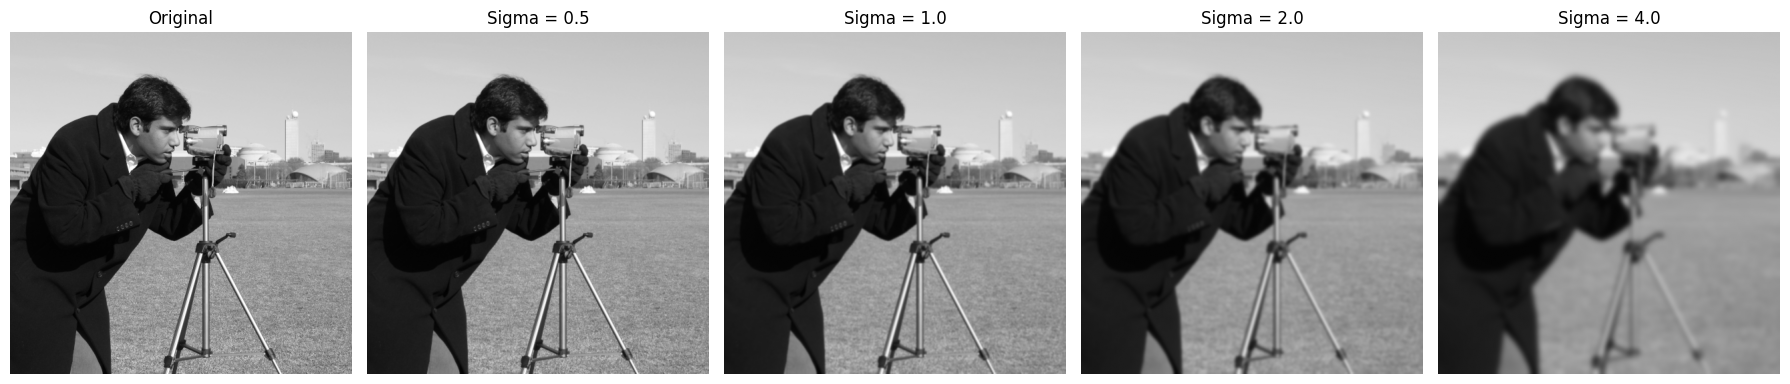

In [2]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Load grayscale sample image
img = data.camera()

# Gaussian blur parameters
sigmas = [0.5, 1.0, 2.0, 4.0]

fig, axes = plt.subplots(1, 5, figsize=(18, 5))

axes[0].imshow(img, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")
axes[0].axis("off")

for ax, sigma in zip(axes[1:], sigmas):

    kernel_size = 2 * int(np.ceil(3 * sigma)) + 1

    blurred = cv2.GaussianBlur(
        img,
        (kernel_size, kernel_size),
        sigmaX=sigma
    )

    ax.imshow(blurred, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Sigma = {sigma}")
    ax.axis("off")

plt.tight_layout()
plt.show()


### Interpreting the sigma sweep

Larger sigma spreads the weights over a wider neighborhood, suppressing fine texture and broadening transitions. This is not a change in the number of output pixels: every result has the original shape. The experiment varies support together with sigma to keep truncation comparable. Gaussian smoothing cannot distinguish unwanted noise from real structure at similar spatial scales.

## 3. Supplementary experiment — derive the kernel and verify separability

Construct a 1D kernel with NumPy, take its outer product, and compare it to the directly sampled 2D formula. A transparent two-pass implementation uses reflected padding and shifted weighted sums. NumPy `reflect` excludes the edge sample, matching OpenCV `BORDER_REFLECT_101`. Floating-point input avoids uint8 rounding differences.

Kernel shape: (13, 13) | sum: 1.0
NumPy/OpenCV maximum absolute error: 7.771561172376096e-16


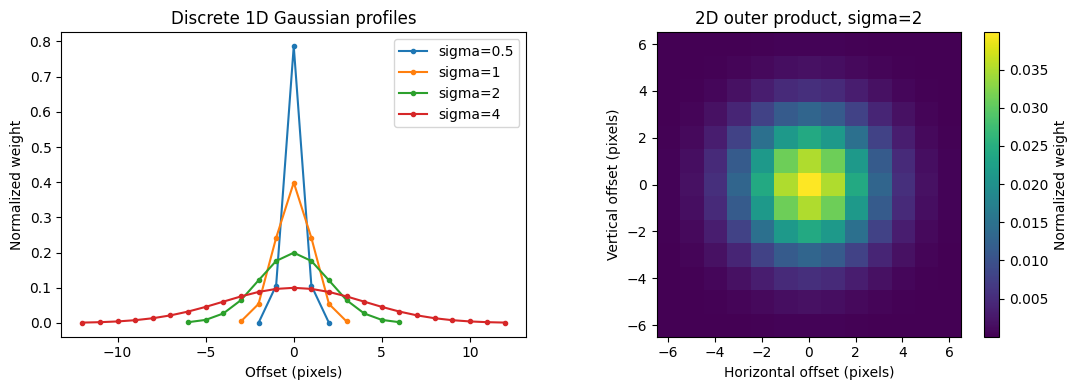

In [3]:
def gaussian_kernel_1d(sigma, radius=None):
    if not np.isfinite(sigma) or sigma <= 0:
        raise ValueError('sigma must be finite and positive')
    if radius is None:
        radius = int(np.ceil(3 * sigma))
    if not isinstance(radius, (int, np.integer)) or radius < 0:
        raise ValueError('radius must be a nonnegative integer')
    offsets = np.arange(-radius, radius + 1, dtype=np.float64)
    weights = np.exp(-0.5 * (offsets / sigma) ** 2)
    return weights / weights.sum()

def separable_filter_numpy(array, weights):
    array = np.asarray(array, dtype=np.float64)
    weights = np.asarray(weights, dtype=np.float64)
    if array.ndim != 2 or weights.ndim != 1 or weights.size % 2 == 0:
        raise ValueError('Expected a 2D image and odd-length 1D weights')
    radius = weights.size // 2
    padded_x = np.pad(array, ((0, 0), (radius, radius)), mode='reflect')
    horizontal = np.zeros_like(array)
    for offset, weight in enumerate(weights):
        horizontal += weight * padded_x[:, offset:offset + array.shape[1]]
    padded_y = np.pad(horizontal, ((radius, radius), (0, 0)), mode='reflect')
    result = np.zeros_like(array)
    for offset, weight in enumerate(weights):
        result += weight * padded_y[offset:offset + array.shape[0], :]
    return result

sigma = 2.0
g = gaussian_kernel_1d(sigma)
radius = len(g) // 2
coordinates = np.arange(-radius, radius + 1)
y_offsets, x_offsets = np.meshgrid(coordinates, coordinates, indexing='ij')
kernel_2d = np.outer(g, g)
direct_2d = np.exp(-(x_offsets ** 2 + y_offsets ** 2) / (2 * sigma ** 2))
direct_2d /= direct_2d.sum()
assert np.allclose(kernel_2d, direct_2d)
assert np.isclose(kernel_2d.sum(), 1) and np.all(g > 0)
assert np.allclose(g, g[::-1])
assert np.allclose(g, cv2.getGaussianKernel(len(g), sigma).ravel())

image_float = img.astype(np.float64) / 255.0
manual_gaussian = separable_filter_numpy(image_float, g)
cv_gaussian = cv2.GaussianBlur(image_float, (len(g), len(g)), sigmaX=sigma,
                              sigmaY=sigma, borderType=cv2.BORDER_REFLECT_101)
print('Kernel shape:', kernel_2d.shape, '| sum:', kernel_2d.sum())
print('NumPy/OpenCV maximum absolute error:', np.max(np.abs(manual_gaussian - cv_gaussian)))
assert np.allclose(manual_gaussian, cv_gaussian, atol=1e-12)
assert np.allclose(separable_filter_numpy(np.ones((16, 16)), g), 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for candidate_sigma in [0.5, 1.0, 2.0, 4.0]:
    weights = gaussian_kernel_1d(candidate_sigma)
    r = len(weights) // 2
    axes[0].plot(np.arange(-r, r + 1), weights, '.-', label=f'sigma={candidate_sigma:g}')
axes[0].set(xlabel='Offset (pixels)', ylabel='Normalized weight', title='Discrete 1D Gaussian profiles')
axes[0].legend()
im = axes[1].imshow(kernel_2d, origin='lower', extent=(-radius - 0.5, radius + 0.5, -radius - 0.5, radius + 0.5))
axes[1].set(xlabel='Horizontal offset (pixels)', ylabel='Vertical offset (pixels)', title='2D outer product, sigma=2')
fig.colorbar(im, ax=axes[1], label='Normalized weight')
plt.tight_layout()
plt.show()

## 4. Supplementary experiment — mean versus Gaussian smoothing

A mean (box) filter assigns identical weight to every position in its support. A Gaussian emphasizes the center. Compare a box of width $k$ with a Gaussian of the **same support**, not necessarily the same smoothing strength. The per-axis variance of an odd-width box is $(k^2-1)/12$; the sampled Gaussian's actual variance is $\sum_u u^2g[u]$. Matching support does not match these variances or their frequency responses.

For independent zero-mean noise with variance $\sigma_n^2$, a linear filter has interior output noise variance

$$\operatorname{Var}(n_{out})=\sigma_n^2\sum_{u,v}K[u,v]^2.$$

The controlled experiment adds unbounded Gaussian noise in normalized units without clipping, preserving the additive-noise model. Display limits clip only the rendering. Compare scene RMSE with the separate filtered-noise standard deviation: they measure different effects.

Same support: 13 × 13
Box per-axis variance: 14.0
Gaussian sampled per-axis variance: 3.9512625830754287
Mean: scene RMSE=0.07422; noise std=0.00466; predicted=0.00462
Gaussian: scene RMSE=0.05135; noise std=0.00857; predicted=0.00848


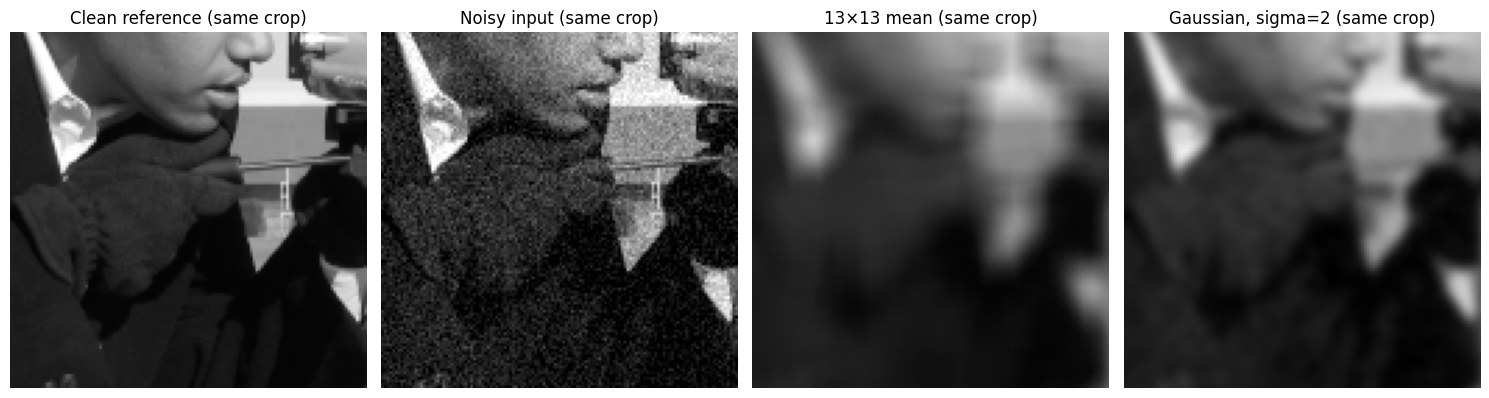

In [4]:
rng = np.random.default_rng(42)
noise = rng.normal(0.0, 0.06, image_float.shape)
noisy_image = image_float + noise
width = len(g)
box_kernel = np.ones((width, width), dtype=np.float64) / width ** 2
mean_result = cv2.filter2D(noisy_image, cv2.CV_64F, box_kernel, borderType=cv2.BORDER_REFLECT_101)
gaussian_result = separable_filter_numpy(noisy_image, g)
print('Same support:', width, '×', width)
print('Box per-axis variance:', (width ** 2 - 1) / 12)
print('Gaussian sampled per-axis variance:', np.sum(coordinates ** 2 * g))
for name, arr, kernel in [('Mean', mean_result, box_kernel), ('Gaussian', gaussian_result, kernel_2d)]:
    filtered_noise = cv2.filter2D(noise, cv2.CV_64F, kernel, borderType=cv2.BORDER_REFLECT_101)
    interior = filtered_noise[radius:-radius, radius:-radius]
    print(f'{name}: scene RMSE={np.sqrt(np.mean((arr - image_float) ** 2)):.5f}; '
          f'noise std={interior.std():.5f}; predicted={0.06 * np.sqrt(np.sum(kernel ** 2)):.5f}')
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, arr, title in zip(axes, [image_float, noisy_image, mean_result, gaussian_result],
                         ['Clean reference', 'Noisy input', f'{width}×{width} mean', 'Gaussian, sigma=2']):
    ax.imshow(arr[160:288, 160:288], cmap='gray', vmin=0, vmax=1)
    ax.set_title(title + ' (same crop)')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Spatial frequency: why Gaussian blur is low-pass

Spatial frequency measures oscillations per pixel. Fine patterns correspond to higher frequencies. With the continuous Fourier convention using cycles per pixel, the ideal Gaussian transfer function is

$$H_\sigma(f_x,f_y)=\exp\left[-2\pi^2\sigma^2(f_x^2+f_y^2)\right].$$

At zero frequency (a constant signal), the gain is 1. Higher frequencies are attenuated more, and increasing sigma narrows the passed band. An ideal Gaussian has no abrupt frequency cutoff. Discrete sampling and finite truncation make the actual response differ from this continuous expression, especially near Nyquist ($0.5$ cycles/pixel) or for small sigma.

For our finite 1D weights, evaluate the discrete-time frequency response directly:

$$H_d(f)=\sum_{u=-r}^r g[u]e^{-2\pi\mathrm{i}fu}.$$

For symmetric kernels it is real (up to numerical precision). A box filter has zeros and sidelobes, whereas the Gaussian response is smoother. Both can blur useful structure; neither is an ideal antialiasing cutoff filter.

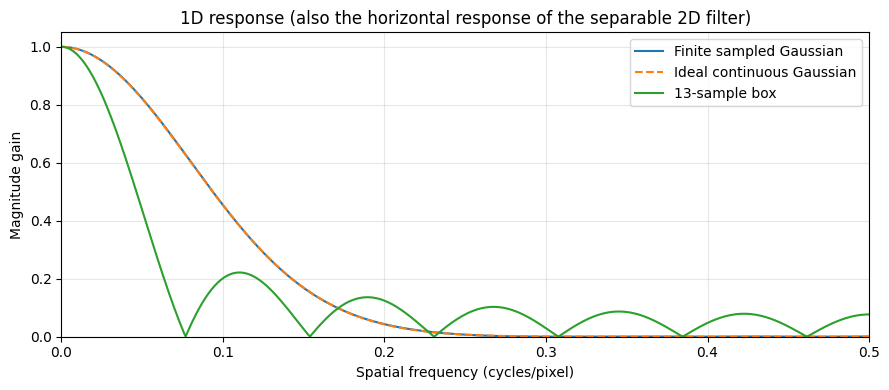

In [5]:
frequencies = np.linspace(0, 0.5, 501)
complex_basis = np.exp(-2j * np.pi * frequencies[:, None] * coordinates[None, :])
gaussian_response = complex_basis @ g
box_response = complex_basis @ np.full(width, 1.0 / width)
ideal_response = np.exp(-2 * np.pi ** 2 * sigma ** 2 * frequencies ** 2)
assert np.isclose(gaussian_response[0], 1) and np.isclose(box_response[0], 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(frequencies, np.abs(gaussian_response), label='Finite sampled Gaussian')
ax.plot(frequencies, ideal_response, '--', label='Ideal continuous Gaussian')
ax.plot(frequencies, np.abs(box_response), label=f'{width}-sample box')
ax.set(xlabel='Spatial frequency (cycles/pixel)', ylabel='Magnitude gain',
       title='1D response (also the horizontal response of the separable 2D filter)',
       xlim=(0, 0.5), ylim=(0, 1.05))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Controlled sinusoidal test

Filter two horizontal sinusoidal patterns. In the interior, a sinusoid is an eigenfunction of a shift-invariant filter: its amplitude is multiplied by $H_d(f)$. Discard the boundary margin when measuring because reflection changes the signal there. Fit sine, cosine, and DC terms rather than estimating amplitude from sampled extrema.

The signals remain in $[0,1]$ and use the same sigma as above. This experiment tests frequency-selective attenuation directly, without interpreting a photograph's unknown frequency mixture.

f=0.02 cycles/pixel | measured gain=0.969268 | predicted=0.969268
f=0.20 cycles/pixel | measured gain=0.043351 | predicted=0.043351


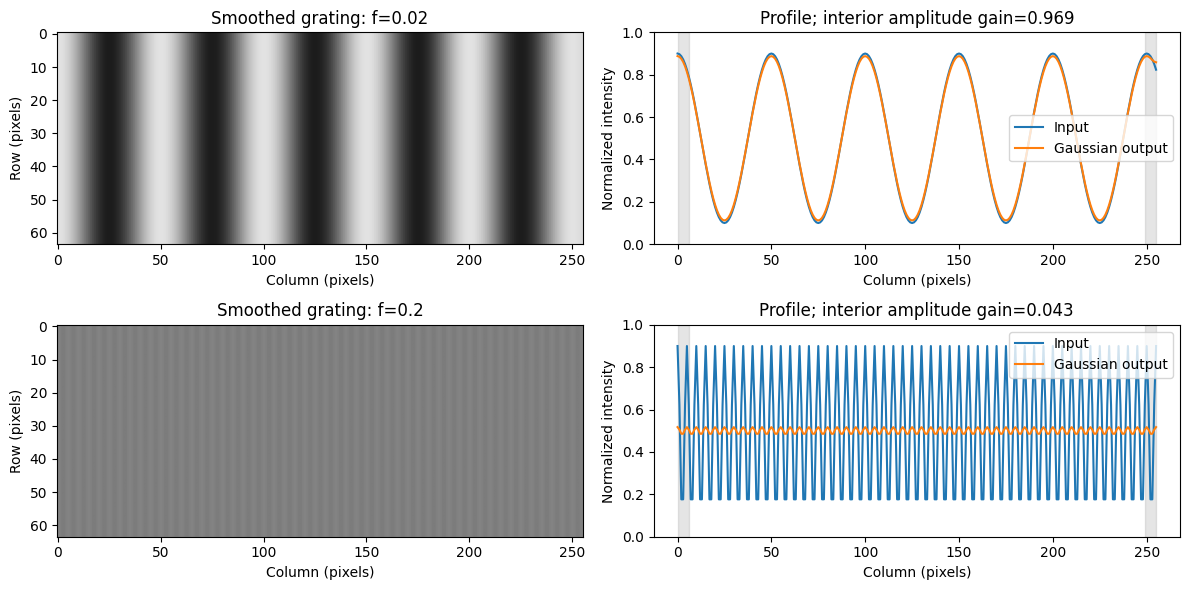

In [6]:
columns = np.arange(256)
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for row_index, frequency in enumerate([0.02, 0.20]):
    signal = 0.5 + 0.4 * np.cos(2 * np.pi * frequency * columns)
    grating = np.tile(signal, (64, 1))
    smoothed = separable_filter_numpy(grating, g)
    valid_columns = columns[radius:-radius]
    phase = 2 * np.pi * frequency * valid_columns
    design = np.column_stack([np.cos(phase), np.sin(phase), np.ones_like(phase)])
    coefficients = np.linalg.lstsq(design, smoothed[32, radius:-radius], rcond=None)[0]
    measured_gain = np.hypot(coefficients[0], coefficients[1]) / 0.4
    expected_gain = abs(np.sum(g * np.exp(-2j * np.pi * frequency * coordinates)))
    print(f'f={frequency:.2f} cycles/pixel | measured gain={measured_gain:.6f} | predicted={expected_gain:.6f}')
    assert np.isclose(measured_gain, expected_gain, atol=1e-10)
    axes[row_index, 0].imshow(smoothed, cmap='gray', vmin=0, vmax=1, aspect='auto')
    axes[row_index, 0].set(title=f'Smoothed grating: f={frequency:g}', xlabel='Column (pixels)', ylabel='Row (pixels)')
    axes[row_index, 1].plot(columns, signal, label='Input')
    axes[row_index, 1].plot(columns, smoothed[32], label='Gaussian output')
    axes[row_index, 1].axvspan(0, radius, color='gray', alpha=0.2)
    axes[row_index, 1].axvspan(255 - radius, 255, color='gray', alpha=0.2)
    axes[row_index, 1].set(xlabel='Column (pixels)', ylabel='Normalized intensity', ylim=(0, 1),
                           title=f'Profile; interior amplitude gain={measured_gain:.3f}')
    axes[row_index, 1].legend()
plt.tight_layout()
plt.show()

## Interpretation, limitations, and review questions

The NumPy/OpenCV comparison verifies normalization, separability, dtype, and boundary handling. The original uint8 experiment includes final rounding; the supplementary float experiment isolates the numerical filter itself. Greater noise reduction alone does not imply better scene recovery: broad averaging also removes real detail.

The two kernels share support but have different variances. For a comparison closer to matched spatial scale, choose a box width and Gaussian sigma with similar per-axis variances, then repeat the experiment. Frequency responses will still differ. The grating experiment shows why high-frequency texture fades more strongly; its gain check excludes boundary effects explicitly.

Gaussian blur is spatially invariant away from boundaries and is not edge-preserving. Truncation, pixel sampling, noise correlation, and padding affect results. Filtering before downsampling can reduce aliasing but requires choosing sigma for the new sampling rate; blur alone cannot recover information already aliased or clipped.

1. Why must a finite sampled Gaussian be renormalized?
2. What is the difference between sigma and kernel radius? What happens if radius stays small as sigma grows?
3. Why are two 1D passes equivalent to the full 2D Gaussian here?
4. Why do same-support mean and Gaussian filters have different noise reduction and detail loss?
5. Derive the ideal frequency at which Gaussian magnitude gain falls to $1/2$ as a function of sigma.
6. Why must the sinusoidal amplitude test exclude the reflected boundaries?
7. How would the noise-variance prediction change for spatially correlated noise?

## Conclusion and connection

Gaussian blur connects local weighted averaging with frequency-selective attenuation. Sigma sets a spatial scale, finite support approximates the infinite kernel, and separability makes the operation efficient. In Computer Vision, Gaussian smoothing supports image pyramids and scale-space analysis; in Signal Processing, it is a smooth low-pass filter. Deep Learning pipelines also use smoothing and multiscale representations, where boundary conventions and preservation of useful detail remain consequential.